# 00 - Build the geometry array for parcellated data

BrainOmni needs three inputs per subject: the signal `X`, a `(C, 6)` array `L` of sensor positions
and orientations, and sensor types `S`. Pooja's parcellated data has only the signal, source
reconstruction discarded the sensor geometry.

Prof Nagarajan's suggestion: reconstruct a usable `L` from the atlas. Each Brainnetome region has a
**centroid** (its center point in 3D), which gives the position. For orientation, use the vector
pointing from the middle of the brain outward to that centroid. That approximates the direction
cortical activity actually has, since cortex wraps the outer surface and its activity runs roughly
perpendicular to it.

**Subcortical caveat.** Brainnetome IDs 1-210 are cortical; 211-246 are subcortical (amygdala,
hippocampus, caudate, globus pallidus, thalamus). The outward-pointing logic is much weaker for
deep structures, which are not on the surface. `CORTICAL_ONLY` controls whether they are dropped.

Outputs to `../results_parcel/`: the geometry array, the region IDs, and the row indices to keep
(so the signal matrix can be subset consistently in notebook 01).

In [1]:
import os, sys, re
os.environ['KMP_DUPLICATE_LIB_OK'] = 'TRUE'
import numpy as np
import nibabel as nib
import matplotlib.pyplot as plt
sys.path.insert(0, '../src')
from matio import load_mat

DATA  = '../data'
ATLAS = f'{DATA}/brainnetome_atlas/BN_Atlas_246_2mm.nii.gz'
OUT   = '../results_parcel'
os.makedirs(OUT, exist_ok=True)

CORTICAL_ONLY = True     # True -> keep IDs 1-210 only; False -> keep all 246
SUBCORTICAL_FROM = 211   # first subcortical ID in Brainnetome

print('cortical only:', CORTICAL_ONLY)

cortical only: True


In [2]:
# Pooja's labels carry the atlas ID as a prefix, e.g. '001 SFG (A8m L)' -> ID 1.
# Her rows are ordered odd-then-even (all left hemisphere, then all right), NOT 1..246,
# so the geometry must follow HER order or every region gets the wrong coordinates.
labels = load_mat(f'{DATA}/ts48/tsAD.mat', keys=['labels'])['labels']
region_ids = np.array([int(re.match(r'(\d+)', l).group(1)) for l in labels])

print(f'{len(labels)} labels parsed')
print('first 5 ids:', region_ids[:5], '| last 5 ids:', region_ids[-5:])
assert sorted(region_ids) == list(range(1, 247)), 'ids do not cover 1..246'
print('ids cover 1..246 exactly')

246 labels parsed
first 5 ids: [1 3 5 7 9] | last 5 ids: [238 240 242 244 246]
ids cover 1..246 exactly


In [3]:
# Centroid of a region = average position of every voxel carrying that ID,
# converted from grid indices to real millimetres via the image affine.
img    = nib.load(ATLAS)
vol    = img.get_fdata()
affine = img.affine
print('atlas volume:', vol.shape)

centroids = {}
for rid in range(1, 247):
    voxels = np.argwhere(vol == rid)
    if len(voxels) == 0:
        print(f'WARNING: region {rid} has no voxels'); continue
    centroids[rid] = nib.affines.apply_affine(affine, voxels.mean(axis=0))

print(f'{len(centroids)} centroids computed')
# Regions 1 and 2 are the left/right halves of one structure, so they should mirror:
# similar y and z, opposite-signed x.
print('region 1 (L):', np.round(centroids[1], 1))
print('region 2 (R):', np.round(centroids[2], 1))

atlas volume: (91, 109, 91)
246 centroids computed
region 1 (L): [-4.7 15.5 53.7]
region 2 (R): [ 7.  16.5 54.2]


In [4]:
# Assemble in Pooja's row order, optionally dropping subcortical regions.
keep = np.arange(len(region_ids))
if CORTICAL_ONLY:
    keep = keep[region_ids < SUBCORTICAL_FROM]
kept_ids = region_ids[keep]
pos = np.stack([centroids[r] for r in kept_ids]).astype(np.float32)   # (C, 3) in mm
print(f'kept {len(kept_ids)} of {len(region_ids)} regions | pos {pos.shape}')

# Match preprocessing.py: centre on the mean, then scale-normalise.
pos -= pos.mean(axis=0)
ori = pos / (np.linalg.norm(pos, axis=1, keepdims=True) + 1e-8)   # unit vectors, outward
scale = np.sqrt(3 * np.mean(np.sum(pos ** 2, axis=1)))
pos /= (scale + 1e-8)

L = np.concatenate([pos, ori], axis=1).astype(np.float32)          # (C, 6)
S = np.ones(len(kept_ids), dtype=np.int32)                         # fabricated: all "gradiometer"
print('geometry array L:', L.shape, '| sensor types S:', S.shape)
print('orientation norms (should all be 1.0):', np.round(np.linalg.norm(ori, axis=1)[:5], 4))

kept 210 of 246 regions | pos (210, 3)
geometry array L: (210, 6) | sensor types S: (210,)
orientation norms (should all be 1.0): [1. 1. 1. 1. 1.]


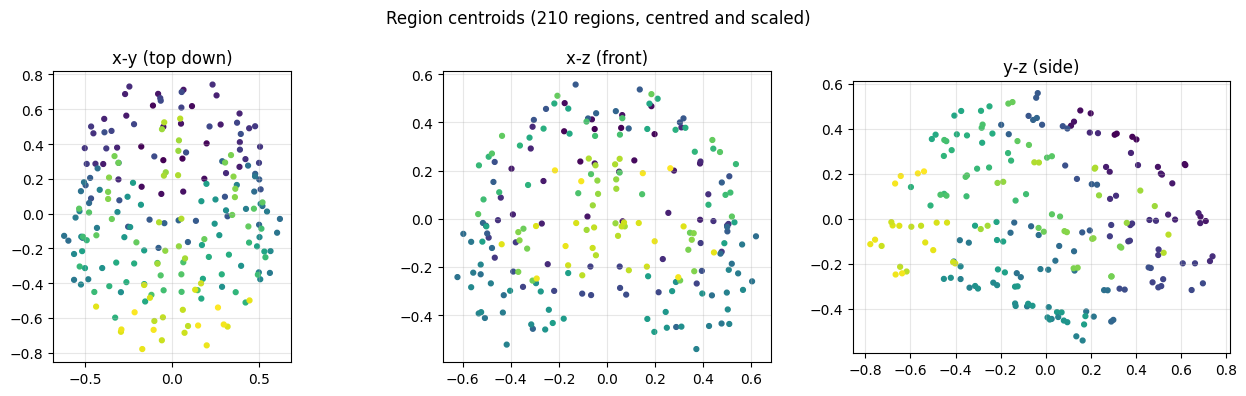

In [5]:
# Sanity plot: this should look like a brain-shaped cloud, not a flat sheet or a blob.
fig = plt.figure(figsize=(13, 4))
views = [('x-y (top down)', 0, 1), ('x-z (front)', 0, 2), ('y-z (side)', 1, 2)]
for i, (title, a, b) in enumerate(views, 1):
    ax = fig.add_subplot(1, 3, i)
    ax.scatter(pos[:, a], pos[:, b], s=12, c=kept_ids, cmap='viridis')
    ax.set_title(title); ax.set_aspect('equal'); ax.grid(alpha=0.3)
fig.suptitle(f'Region centroids ({len(kept_ids)} regions, centred and scaled)')
plt.tight_layout(); plt.savefig(f'{OUT}/parcel_geometry_check.png', dpi=150); plt.show()

In [6]:
suffix = 'cortical' if CORTICAL_ONLY else 'all'
np.save(f'{OUT}/parcel_L_{suffix}.npy', L)
np.save(f'{OUT}/parcel_S_{suffix}.npy', S)
np.save(f'{OUT}/parcel_ids_{suffix}.npy', kept_ids)
np.save(f'{OUT}/parcel_keep_idx_{suffix}.npy', keep)   # rows to take from Pooja's signal matrix
print(f'saved to {OUT}/ with suffix _{suffix}')
print(f'  L {L.shape} | S {S.shape} | ids {kept_ids.shape} | keep_idx {keep.shape}')

saved to ../results_parcel/ with suffix _cortical
  L (210, 6) | S (210,) | ids (210,) | keep_idx (210,)
